In [1]:
import pandas as pd

df = pd.read_excel('/Users/riteshpardeshi/RETAIL.xlsx')

In [3]:
df.head()

,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost
0,Central,Antigua,Baby Food,Online,Medium,2019-12-20,957081544.0,2019-01-11,552,255.28,159.42
1,Central,Panama,Snacks,Offline,Cancelled,2022-07-05,301644504.0,2022-07-26,2167,152.58,97.44
2,Europe,Czech Rep.,Beverages,Offline,Cancelled,2021-09-12,478051030.0,2021-09-29,4778,47.45,31.79
3,Asia,North Korea,Cereal,Offline,Low,2022-05-13,892599952.0,2022-06-15,9016,205.70,117.11
4,Asia,Sri Lanka,Snacks,Offline,Cancelled,2015-07-20,571902596.0,2015-07-27,7542,152.58,97.44


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5002 entries, 0 to 5001
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Region          5002 non-null   object        
 1   Country         5001 non-null   object        
 2   Item Type       5002 non-null   object        
 3   Sales Channel   5002 non-null   object        
 4   Order Priority  5002 non-null   object        
 5   Order Date      5002 non-null   datetime64[ns]
 6   Order ID        5000 non-null   float64       
 7   Ship Date       5002 non-null   datetime64[ns]
 8   Units Sold      5001 non-null   object        
 9   Unit Price      5002 non-null   float64       
 10  Unit Cost       5002 non-null   float64       
dtypes: datetime64[ns](2), float64(3), object(6)
memory usage: 430.0+ KB


In [13]:
df.shape

(5002, 11)

In [17]:
df.describe()

,Order Date,Order ID,Ship Date,Unit Price,Unit Cost
count,5002,5.000000e+03,5002,5002.000000,5002.000000
mean,2019-01-15 04:51:37.640943872,5.487314e+08,2019-01-18 04:32:20.343862528,265.777749,187.503693
min,2015-01-02 00:00:00,1.000909e+08,2015-01-01 00:00:00,9.330000,6.920000
25%,2016-11-15 00:00:00,3.205064e+08,2016-11-19 06:00:00,81.730000,35.840000
50%,2019-03-09 00:00:00,5.523150e+08,2019-03-16 12:00:00,154.060000,97.440000
75%,2021-01-27 18:00:00,7.687709e+08,2021-01-14 18:00:00,437.200000,263.330000
max,2022-12-30 00:00:00,9.998797e+08,2022-12-31 00:00:00,668.270000,524.960000
std,NaN,2.593963e+08,NaN,218.686444,176.384707


In [21]:
df['Units Sold'] = pd.to_numeric(df['Units Sold'],errors = 'coerce')

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5002 entries, 0 to 5001
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Region          5002 non-null   object        
 1   Country         5001 non-null   object        
 2   Item Type       5002 non-null   object        
 3   Sales Channel   5002 non-null   object        
 4   Order Priority  5002 non-null   object        
 5   Order Date      5002 non-null   datetime64[ns]
 6   Order ID        5000 non-null   float64       
 7   Ship Date       5002 non-null   datetime64[ns]
 8   Units Sold      5000 non-null   float64       
 9   Unit Price      5002 non-null   float64       
 10  Unit Cost       5002 non-null   float64       
dtypes: datetime64[ns](2), float64(4), object(5)
memory usage: 430.0+ KB


In [27]:
df.isnull().sum()

Region            0
Country           1
Item Type         0
Sales Channel     0
Order Priority    0
Order Date        0
Order ID          2
Ship Date         0
Units Sold        2
Unit Price        0
Unit Cost         0
dtype: int64

In [31]:
df.dropna(axis=0).shape

(4997, 11)

In [33]:
for i in df.columns:
    print(i)

Region
Country
Item Type
Sales Channel
Order Priority
Order Date
Order ID
Ship Date
Units Sold
Unit Price
Unit Cost


In [37]:
for i in df.dropna(axis=1).columns:
    print(i)

Region
Item Type
Sales Channel
Order Priority
Order Date
Ship Date
Unit Price
Unit Cost


In [43]:
df.drop(['Order ID'],axis = 1, inplace=True)

In [45]:
df.columns

Index(['Region', 'Country', 'Item Type', 'Sales Channel', 'Order Priority',
       'Order Date', 'Ship Date', 'Units Sold', 'Unit Price', 'Unit Cost'],
      dtype='object')

In [49]:
df.isna().sum()

Region            0
Country           1
Item Type         0
Sales Channel     0
Order Priority    0
Order Date        0
Ship Date         0
Units Sold        2
Unit Price        0
Unit Cost         0
dtype: int64

In [53]:
df['Country'].isna().sum()

1

In [57]:
df[df['Country'].isna()]

,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Ship Date,Units Sold,Unit Price,Unit Cost
4975,Pacific,NaN,Meat,Online,Cancelled,2016-04-12,2016-05-13,1791.0,421.89,364.69


In [59]:
df.dropna(subset='Country',inplace=True)

In [61]:
df.isna().sum()

Region            0
Country           0
Item Type         0
Sales Channel     0
Order Priority    0
Order Date        0
Ship Date         0
Units Sold        2
Unit Price        0
Unit Cost         0
dtype: int64

In [73]:
df[(df['Country'] == 'Malaysia') & (df['Item Type'] == 'Office Supplies') & (df['Sales Channel'] == 'Offline') & (df['Order Priority'] == 'Low')]

,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Ship Date,Units Sold,Unit Price,Unit Cost
4974,Asia,Malaysia,Office Supplies,Offline,Low,2021-11-25,2021-12-26,NaN,651.21,524.96


In [76]:
df[(df['Country'] == 'Malaysia') & (df['Item Type'] == 'Office Supplies')]

,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Ship Date,Units Sold,Unit Price,Unit Cost
1974,Asia,Malaysia,Office Supplies,Offline,High,2015-01-24,2015-01-28,6526.0,651.21,524.96
4201,Asia,Malaysia,Office Supplies,Online,Low,2018-09-27,2018-10-19,2482.0,651.21,524.96
4974,Asia,Malaysia,Office Supplies,Offline,Low,2021-11-25,2021-12-26,NaN,651.21,524.96


In [80]:
meanval = df[(df['Country'] == 'Malaysia') & (df['Item Type'] == 'Office Supplies')]['Units Sold'].mean()

In [82]:
meanval

4504.0

In [88]:
df['Units Sold'].fillna(meanval,inplace=True)

/var/folders/d9/zn0fzv5j3wv4ldx8c1wgtq9h0000gn/T/ipykernel_13124/3622814752.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Units Sold'].fillna(meanval,inplace=True)


In [90]:
df.isna().sum()

Region            0
Country           0
Item Type         0
Sales Channel     0
Order Priority    0
Order Date        0
Ship Date         0
Units Sold        0
Unit Price        0
Unit Cost         0
dtype: int64

In [92]:
df.columns

Index(['Region', 'Country', 'Item Type', 'Sales Channel', 'Order Priority',
       'Order Date', 'Ship Date', 'Units Sold', 'Unit Price', 'Unit Cost'],
      dtype='object')

In [94]:
df.columns = df.columns.str.strip().str.replace(' ','_')

In [96]:
df.columns

Index(['Region', 'Country', 'Item_Type', 'Sales_Channel', 'Order_Priority',
       'Order_Date', 'Ship_Date', 'Units_Sold', 'Unit_Price', 'Unit_Cost'],
      dtype='object')

In [98]:
df['Input_Cost'] = df.Units_Sold * df.Unit_Cost

In [100]:
df['Revenue'] = df.Units_Sold * df.Unit_Price

In [102]:
df['Profit'] = df.Revenue - df.Input_Cost

In [104]:
df

,Region,Country,Item_Type,Sales_Channel,Order_Priority,Order_Date,Ship_Date,Units_Sold,Unit_Price,Unit_Cost,Input_Cost,Revenue,Profit
0,Central,Antigua,Baby Food,Online,Medium,2019-12-20,2019-01-11,552.0,255.28,159.42,87999.84,140914.56,52914.72
1,Central,Panama,Snacks,Offline,Cancelled,2022-07-05,2022-07-26,2167.0,152.58,97.44,211152.48,330640.86,119488.38
2,Europe,Czech Rep.,Beverages,Offline,Cancelled,2021-09-12,2021-09-29,4778.0,47.45,31.79,151892.62,226716.10,74823.48
3,Asia,North Korea,Cereal,Offline,Low,2022-05-13,2022-06-15,9016.0,205.70,117.11,1055863.76,1854591.20,798727.44
4,Asia,Sri Lanka,Snacks,Offline,Cancelled,2015-07-20,2015-07-27,7542.0,152.58,97.44,734892.48,1150758.36,415865.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4997,Asia,Myanmar,Baby Food,Offline,High,2016-11-23,2016-12-10,5204.0,255.28,159.42,829621.68,1328477.12,498855.44
4998,Europe,Finland,Clothes,Online,Low,2018-04-22,2018-05-11,9410.0,109.28,35.84,337254.40,1028324.80,691070.40
4999,Africa,Tanzania,Vegetables,Online,Low,2021-07-08,2021-08-07,2450.0,154.06,90.93,222778.50,377447.00,154668.50
5000,Central,Saint Vincent,Baby Food,Online,Low,2022-11-28,2022-12-03,6428.0,255.28,159.42,1024751.76,1640939.84,616188.08


In [108]:
df.duplicated().sum()

2

In [116]:
df[df.duplicated(keep='first')]

,Region,Country,Item_Type,Sales_Channel,Order_Priority,Order_Date,Ship_Date,Units_Sold,Unit_Price,Unit_Cost,Input_Cost,Revenue,Profit
5000,Central,Saint Vincent,Baby Food,Online,Low,2022-11-28,2022-12-03,6428.0,255.28,159.42,1024751.76,1640939.84,616188.08
5001,Africa,Liberia,Cosmetics,Offline,Medium,2020-06-17,2020-06-23,8195.0,437.20,263.33,2157989.35,3582854.00,1424864.65


In [120]:
df[df.duplicated(keep=False)]

,Region,Country,Item_Type,Sales_Channel,Order_Priority,Order_Date,Ship_Date,Units_Sold,Unit_Price,Unit_Cost,Input_Cost,Revenue,Profit
14,Central,Saint Vincent,Baby Food,Online,Low,2022-11-28,2022-12-03,6428.0,255.28,159.42,1024751.76,1640939.84,616188.08
4994,Africa,Liberia,Cosmetics,Offline,Medium,2020-06-17,2020-06-23,8195.0,437.20,263.33,2157989.35,3582854.00,1424864.65
5000,Central,Saint Vincent,Baby Food,Online,Low,2022-11-28,2022-12-03,6428.0,255.28,159.42,1024751.76,1640939.84,616188.08
5001,Africa,Liberia,Cosmetics,Offline,Medium,2020-06-17,2020-06-23,8195.0,437.20,263.33,2157989.35,3582854.00,1424864.65


In [124]:
df.drop_duplicates(keep = 'first',inplace=True)

In [126]:
df.duplicated().sum()

0

In [128]:
df.reset_index(inplace=True)

In [130]:
df

,index,Region,Country,Item_Type,Sales_Channel,Order_Priority,Order_Date,Ship_Date,Units_Sold,Unit_Price,Unit_Cost,Input_Cost,Revenue,Profit
0,0,Central,Antigua,Baby Food,Online,Medium,2019-12-20,2019-01-11,552.0,255.28,159.42,87999.84,140914.56,52914.72
1,1,Central,Panama,Snacks,Offline,Cancelled,2022-07-05,2022-07-26,2167.0,152.58,97.44,211152.48,330640.86,119488.38
2,2,Europe,Czech Rep.,Beverages,Offline,Cancelled,2021-09-12,2021-09-29,4778.0,47.45,31.79,151892.62,226716.10,74823.48
3,3,Asia,North Korea,Cereal,Offline,Low,2022-05-13,2022-06-15,9016.0,205.70,117.11,1055863.76,1854591.20,798727.44
4,4,Asia,Sri Lanka,Snacks,Offline,Cancelled,2015-07-20,2015-07-27,7542.0,152.58,97.44,734892.48,1150758.36,415865.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,4995,Pacific,New Zealand,Household,Offline,Cancelled,2015-04-03,2015-04-20,5305.0,668.27,502.54,2665974.70,3545172.35,879197.65
4995,4996,MENA,Azerbaijan,Clothes,Offline,Low,2018-08-17,2018-10-02,1077.0,109.28,35.84,38599.68,117694.56,79094.88
4996,4997,Asia,Myanmar,Baby Food,Offline,High,2016-11-23,2016-12-10,5204.0,255.28,159.42,829621.68,1328477.12,498855.44
4997,4998,Europe,Finland,Clothes,Online,Low,2018-04-22,2018-05-11,9410.0,109.28,35.84,337254.40,1028324.80,691070.40


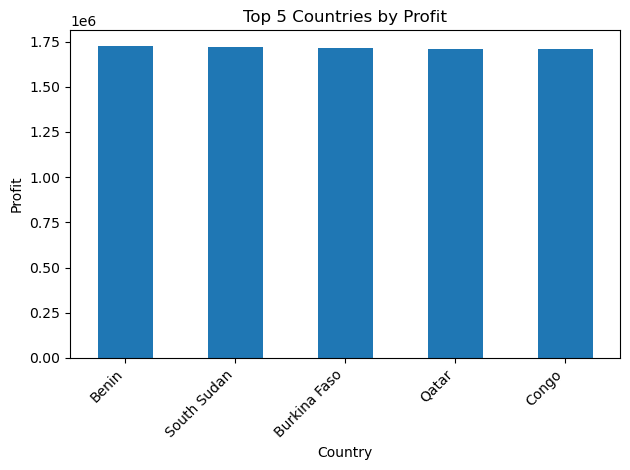

In [150]:
df.sort_values(by='Profit',ascending=False)[['Profit','Country']].head(5).set_index('Country').plot(kind='bar',legend=False)

plt.title("Top 5 Countries by Profit")
plt.xlabel("Country")
plt.ylabel("Profit")

# Rotate x-axis labels if country names are long so they don't overlap
plt.xticks(rotation=45, ha="right")

# Display the plot
plt.tight_layout()
plt.show()

In [148]:
import matplotlib.pyplot as plt

In [152]:
df

,index,Region,Country,Item_Type,Sales_Channel,Order_Priority,Order_Date,Ship_Date,Units_Sold,Unit_Price,Unit_Cost,Input_Cost,Revenue,Profit
0,0,Central,Antigua,Baby Food,Online,Medium,2019-12-20,2019-01-11,552.0,255.28,159.42,87999.84,140914.56,52914.72
1,1,Central,Panama,Snacks,Offline,Cancelled,2022-07-05,2022-07-26,2167.0,152.58,97.44,211152.48,330640.86,119488.38
2,2,Europe,Czech Rep.,Beverages,Offline,Cancelled,2021-09-12,2021-09-29,4778.0,47.45,31.79,151892.62,226716.10,74823.48
3,3,Asia,North Korea,Cereal,Offline,Low,2022-05-13,2022-06-15,9016.0,205.70,117.11,1055863.76,1854591.20,798727.44
4,4,Asia,Sri Lanka,Snacks,Offline,Cancelled,2015-07-20,2015-07-27,7542.0,152.58,97.44,734892.48,1150758.36,415865.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,4995,Pacific,New Zealand,Household,Offline,Cancelled,2015-04-03,2015-04-20,5305.0,668.27,502.54,2665974.70,3545172.35,879197.65
4995,4996,MENA,Azerbaijan,Clothes,Offline,Low,2018-08-17,2018-10-02,1077.0,109.28,35.84,38599.68,117694.56,79094.88
4996,4997,Asia,Myanmar,Baby Food,Offline,High,2016-11-23,2016-12-10,5204.0,255.28,159.42,829621.68,1328477.12,498855.44
4997,4998,Europe,Finland,Clothes,Online,Low,2018-04-22,2018-05-11,9410.0,109.28,35.84,337254.40,1028324.80,691070.40


In [158]:
df[df['Region'].eq('Africa')]['Country'].count()

1285

In [162]:
df[df['Order_Priority'].ne('Cancelled')]['Region'].count()

3826

In [166]:
df[df['Units_Sold'].gt(df['Units_Sold'].mean())]['Region'].count()

2546

In [170]:
df.groupby('Region')['Units_Sold'].sum()

Region
Africa           6611070.0
Asia             3618876.0
Central          2698776.0
Europe           6586398.0
MENA             3013431.0
North America     484760.0
Pacific          2109995.0
Name: Units_Sold, dtype: float64

In [172]:
df.groupby(['Region','Country'])['Units_Sold'].sum()

Region   Country        
Africa   Africa             117194.0
         Angola              75139.0
         Benin              153672.0
         Botswana           136932.0
         Burkina Faso       132982.0
                              ...   
Pacific  Samoa              173567.0
         Solomon Islands    165148.0
         Tonga              183640.0
         Tuvalu             104539.0
         Vanuatu            173850.0
Name: Units_Sold, Length: 188, dtype: float64

In [174]:
df.groupby('Country')['Units_Sold'].agg(['mean','sum'])

,mean,sum
Country,,
Afghanistan,4091.421053,77737.0
Africa,4507.461538,117194.0
Albania,4314.666667,90608.0
Algeria,4757.071429,133198.0
Andorra,4642.150000,185686.0
...,...,...
Vatican City,4308.739130,99101.0
Vietnam,4543.736842,86331.0
Yemen,4931.772727,108499.0


In [178]:
df.groupby('Country')['Units_Sold'].sum().sort_values(ascending=False)

Country
Guinea        366852.0
Congo         314760.0
Grenada       205943.0
Macedonia     203078.0
Myanmar       199967.0
                ...   
Trinidad        5172.0
Czech Rep.      4778.0
Saudi           3407.0
Bosnia           927.0
Antigua          552.0
Name: Units_Sold, Length: 188, dtype: float64

In [180]:
#3. Find the country and the Units sold where the number of units sold is greater than the mean of the region

In [184]:
df[df['Units_Sold','Country']].gt(df.groupby('Region')['Units_Sold'].mean()

SyntaxError: incomplete input (2580144606.py, line 1)

In [188]:
meanreg = df.groupby('Region')['Units_Sold'].mean()

In [210]:
df.groupby('Country')['Units_Sold'] > meanreg

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 2 dimensions. The detected shape was (188, 2) + inhomogeneous part.

In [220]:
df['Region_mean'] = df.groupby('Region')['Units_Sold'].transform('mean')

df.head(50)

,index,Region,Country,Item_Type,Sales_Channel,Order_Priority,Order_Date,Ship_Date,Units_Sold,Unit_Price,Unit_Cost,Input_Cost,Revenue,Profit,Region_mean
0,0,Central,Antigua,Baby Food,Online,Medium,2019-12-20,2019-01-11,552.0,255.28,159.42,87999.84,140914.56,52914.72,5053.887640
1,1,Central,Panama,Snacks,Offline,Cancelled,2022-07-05,2022-07-26,2167.0,152.58,97.44,211152.48,330640.86,119488.38,5053.887640
2,2,Europe,Czech Rep.,Beverages,Offline,Cancelled,2021-09-12,2021-09-29,4778.0,47.45,31.79,151892.62,226716.10,74823.48,4952.178947
3,3,Asia,North Korea,Cereal,Offline,Low,2022-05-13,2022-06-15,9016.0,205.70,117.11,1055863.76,1854591.20,798727.44,5033.207232
4,4,Asia,Sri Lanka,Snacks,Offline,Cancelled,2015-07-20,2015-07-27,7542.0,152.58,97.44,734892.48,1150758.36,415865.88,5033.207232
5,5,MENA,Morocco,Personal Care,Offline,Low,2022-11-08,2022-11-22,48.0,81.73,56.67,2720.16,3923.04,1202.88,4940.050820
6,6,Pacific,Micronesia,Clothes,Offline,High,2021-03-28,2021-05-10,8258.0,109.28,35.84,295966.72,902434.24,606467.52,5084.325301
7,7,Europe,Bosnia,Clothes,Online,Medium,2019-10-14,2019-11-04,927.0,109.28,35.84,33223.68,101302.56,68078.88,4952.178947
8,8,MENA,Afghanistan,Clothes,Offline,Medium,2016-08-27,2016-10-05,8841.0,109.28,35.84,316861.44,966144.48,649283.04,4940.050820
9,9,Africa,Ethiopia,Baby Food,Online,Medium,2015-04-13,2015-05-07,9817.0,255.28,159.42,1565026.14,2506083.76,941057.62,5144.801556


In [224]:
greater_than = df[df['Units_Sold'] > df['Region_mean']]

In [228]:
greater_than[['Country','Units_Sold']]

,Country,Units_Sold
3,North Korea,9016.0
4,Sri Lanka,7542.0
6,Micronesia,8258.0
8,Afghanistan,8841.0
9,Ethiopia,9817.0
...,...,...
4992,Denmark,7088.0
4993,Liberia,8195.0
4994,New Zealand,5305.0
4996,Myanmar,5204.0


In [236]:
#4. Find the country with the highest number of unit sold


df.groupby('Country')['Units_Sold'].max().idxmax()

'United Kingdom'

In [244]:
df.groupby('Country')['Units_Sold'].max().reset_index().sort_values(by='Units_Sold',ascending=False).head(5)

,Country,Units_Sold
180,United Kingdom,9999.0
131,Portugal,9997.0
73,Ireland,9996.0
44,Dominica,9996.0
164,Thailand,9991.0


In [252]:
df.groupby('Country')['Units_Sold'].max().reset_index().sort_values(by='Units_Sold')

,Country,Units_Sold
6,Antigua,552.0
21,Bosnia,927.0
140,Saudi,3407.0
40,Czech Rep.,4778.0
170,Trinidad,5172.0
...,...,...
164,Thailand,9991.0
44,Dominica,9996.0
73,Ireland,9996.0
131,Portugal,9997.0


In [268]:
#1 Region and items wise total profit
pd.pivot_table(data=df,
                index='Region',
               columns='Item_Type',
               values='Profit',
               aggfunc='sum').round(1)

Item_Type,Baby Food,Beverages,Cereal,Clothes,Cosmetics,Fruits,Household,Meat,Office Supplies,Personal Care,Snacks,Vegetables
Region,,,,,,,,,,,,
Africa,58938083.1,8139379.0,41440098.7,32774876.6,106485464.4,1578424.7,99281053.7,26825541.6,78915213.8,14799283.2,28222637.0,31536023.3
Asia,32326867.8,5274632.5,26760026.9,22068059.0,50145672.8,934429.3,58379055.4,13742128.4,28673900.0,7592052.3,14630737.3,17563649.8
Central,22887725.3,3427801.7,21640853.8,15081197.8,34207879.3,582851.3,35482793.0,13863392.4,21485225.0,5193634.9,13844330.6,16914294.6
Europe,53940997.2,9601662.8,41255034.2,43431314.4,92723306.2,1425929.5,72962466.8,30509107.2,77977176.2,14045628.8,27027422.4,37033320.6
MENA,26163549.1,3546238.3,22366494.5,19625077.4,42086450.6,710651.2,44253058.9,13471858.4,23725026.2,7370396.6,12345790.9,15715708.5
North America,2532333.6,1270245.2,2094976.3,1469681.3,7813196.2,76035.5,11856324.2,1506247.6,8262683.8,869055.7,1658280.4,1831338.2
Pacific,20914159.6,3319967.0,16601234.5,11213994.2,38951748.4,333688.6,25691961.8,8727747.6,26902360.0,3630417.1,7807382.9,10737466.0


In [266]:
df.groupby(['Region','Item_Type'])['Profit'].sum().reset_index().sort_values(by='Profit',ascending=False).round(1)

,Region,Item_Type,Profit
4,Africa,Cosmetics,106485464.4
6,Africa,Household,99281053.7
40,Europe,Cosmetics,92723306.2
8,Africa,Office Supplies,78915213.8
44,Europe,Office Supplies,77977176.2
...,...,...,...
69,North America,Personal Care,869055.7
53,MENA,Fruits,710651.2
29,Central,Fruits,582851.3
77,Pacific,Fruits,333688.6


In [270]:
pd.pivot_table(df,
              index='Region',
              columns='Item_Type',
              values=['Profit','Units_Sold'],
              aggfunc='sum').round(1)

Profit                                                  \
Item_Type       Baby Food  Beverages      Cereal     Clothes    Cosmetics   
Region                                                                      
Africa         58938083.1  8139379.0  41440098.7  32774876.6  106485464.4   
Asia           32326867.8  5274632.5  26760026.9  22068059.0   50145672.8   
Central        22887725.3  3427801.7  21640853.8  15081197.8   34207879.3   
Europe         53940997.2  9601662.8  41255034.2  43431314.4   92723306.2   
MENA           26163549.1  3546238.3  22366494.5  19625077.4   42086450.6   
North America   2532333.6  1270245.2   2094976.3   1469681.3    7813196.2   
Pacific        20914159.6  3319967.0  16601234.5  11213994.2   38951748.4   

                                                                  \
Item_Type         Fruits   Household        Meat Office Supplies   
Region                                                             
Africa         1578424.7  99281053.7  26825541.6      78915213.8   
Asia            934429.3  58379055.4  13742128.4      28673900.0   
Central         582851.3  35482793.0  13863392.4      21485225.0   
Europe         1425929.5  72962466.8  30509107.2      77977176.2   
MENA            710651.2  44253058.9  13471858.4      23725026.2   
North America    76035.5  11856324.2   1506247.6       8262683.8   
Pacific         333688.6  25691961.8   8727747.6      26902360.0   

                             ... Units_Sold                                \
Item_Type     Personal Care  ...     Cereal   Clothes Cosmetics    Fruits   
Region                       ...                                            
Africa           14799283.2  ...   467774.0  446281.0  612443.0  654948.0   
Asia              7592052.3  ...   302066.0  300491.0  288409.0  387730.0   
Central           5193634.9  ...   244281.0  205354.0  196744.0  241847.0   
Europe           14045628.8  ...   465685.0  591385.0  533291.0  591672.0   
MENA              7370396.6  ...   252472.0  267226.0  242057.0  294876.0   
North America      869055.7  ...    23648.0   20012.0   44937.0   31550.0   
Pacific           3630417.1  ...   187394.0  152696.0  224028.0  138460.0   

                                                                           \
Item_Type     Household      Meat Office Supplies Personal Care    Snacks   
Region                                                                      
Africa         599053.0  468978.0        625071.0      590554.0  511836.0   
Asia           352254.0  240247.0        227120.0      302955.0  265338.0   
Central        214100.0  242367.0        170180.0      207248.0  251076.0   
Europe         440249.0  533376.0        617641.0      560480.0  490160.0   
MENA           267019.0  235522.0        187921.0      294110.0  223899.0   
North America   71540.0   26333.0         65447.0       34679.0   30074.0   
Pacific        155023.0  152583.0        213088.0      144869.0  141592.0   

                          
Item_Type     Vegetables  
Region                    
Africa          499541.0  
Asia            278214.0  
Central         267928.0  
Europe          586620.0  
MENA            248942.0  
North America    29009.0  
Pacific         170085.0  

[7 rows x 24 columns]

In [274]:
pd.pivot_table(df
              ,index='Region',
              columns='Item_Type',
              values= ['Profit','Units_Sold'],
              aggfunc=['sum','mean'])


sum                                        \
                    Profit                                         
Item_Type        Baby Food   Beverages       Cereal      Clothes   
Region                                                             
Africa         58938083.10  8139378.96  41440098.66  32774876.64   
Asia           32326867.80  5274632.52  26760026.94  22068059.04   
Central        22887725.32  3427801.74  21640853.79  15081197.76   
Europe         53940997.16  9601662.78  41255034.15  43431314.40   
MENA           26163549.10  3546238.32  22366494.48  19625077.44   
North America   2532333.62  1270245.24   2094976.32   1469681.28   
Pacific        20914159.64  3319966.98  16601234.46  11213994.24   

                                                                  \
                                                                   
Item_Type         Cosmetics      Fruits    Household        Meat   
Region                                                             
Africa         1.064855e+08  1578424.68  99281053.69  26825541.6   
Asia           5.014567e+07   934429.30  58379055.42  13742128.4   
Central        3.420788e+07   582851.27  35482793.00  13863392.4   
Europe         9.272331e+07  1425929.52  72962466.77  30509107.2   
MENA           4.208645e+07   710651.16  44253058.87  13471858.4   
North America  7.813196e+06    76035.50  11856324.20   1506247.6   
Pacific        3.895175e+07   333688.60  25691961.79   8727747.6   

                                             ...         mean               \
                                             ...   Units_Sold                
Item_Type     Office Supplies Personal Care  ...       Cereal      Clothes   
Region                                       ...                             
Africa            78915213.75   14799283.24  ...  5255.887640  5014.393258   
Asia              28673900.00    7592052.30  ...  4951.901639  5008.183333   
Central           21485225.00    5193634.88  ...  5428.466667  5133.850000   
Europe            77977176.25   14045628.80  ...  4521.213592  5632.238095   
MENA              23725026.25    7370396.60  ...  5371.744681  4858.654545   
North America      8262683.75     869055.74  ...  3941.333333  4002.400000   
Pacific           26902360.00    3630417.14  ...  5511.588235  4771.750000   

                                                                   \
                                                                    
Item_Type        Cosmetics       Fruits    Household         Meat   
Region                                                              
Africa         5372.307018  5745.157895  5396.873874  4689.780000   
Asia           4806.816667  5239.594595  5503.968750  4449.018519   
Central        4918.600000  5038.479167  4979.069767  4406.672727   
Europe         4677.991228  5282.785714  4538.649485  4805.189189   
MENA           5150.148936  4914.600000  4684.543860  5352.772727   
North America  4493.700000  3505.555556  5110.000000  5266.600000   
Pacific        5744.307692  4615.333333  4079.552632  5261.482759   

                                                                       
                                                                       
Item_Type     Office Supplies Personal Care       Snacks   Vegetables  
Region                                                                 
Africa            5388.543103   5368.672727  5067.683168  4582.944954  
Asia              4635.102041   5223.362069  4574.793103  6182.533333  
Central           4727.222222   5453.894737  5342.042553  5152.461538  
Europe            5021.471545   4873.739130  4758.834951  5145.789474  
MENA              4474.309524   5070.862069  4763.808511  4881.215686  
North America     5453.916667   3853.222222  3341.555556  4144.142857  
Pacific           5073.523810   5365.518519  4290.666667  5315.156250  

[7 rows x 48 columns]